# 04 — Fire hotspots by source region (Bogotá)

**Revised (v7)**: the original version of this notebook used three named circles for
"CVB", "eastern plains" and "north Colombia" that were our own unsourced approximations
of regions the paper names but doesn't give exact coordinates for. The user flagged this
after noticing only `hotspots_cvb` ever got selected, never Caquetá or the plains, and
asked to go back to Casallas et al. 2024 (STOTEN 906:167350, "Air pollution analysis in
Northwestern South America: A new Lagrangian framework") directly. Checking the
supplementary Fig. SM33 (actual mean hotspot count by season, not our proxy) confirmed
this was a real bug: NWSA's DJF/MAM hotspot activity is **one large, continuous band**
sweeping from the Venezuela border through the Llanos (roughly 4-12N, 76-68W), not three
separable clusters -- our three circles placed inside that one band were highly
collinear by construction (cvb/eastern_plains centers were only 283km apart against a
700km combined radius), which is why SFS only ever picked one of them.

Fix: keep the three point sources with **exact paper-quoted coordinates** (Caquetá,
Magdalena Valley, Nevados -- geographically distinct, low mutual overlap; radii
trimmed further to reduce what overlap remained), and replace the invented
northern-band circles with **8 compass-direction sectors from Bogotá**
(`load_hotspots_daily_by_sector`) -- non-overlapping by construction, and actually the
paper's *own* method for relating source direction to plume arrivals (their Fig. 6f is
a season x 8-direction matrix), rather than us guessing region boundaries.

**Coverage gap** (unchanged): this hotspot product only covers through 2023-12-31, while
the cleaned PM2.5 network series runs to 2026.


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("/path/to/project")
sys.path.insert(0, str(PROJECT_ROOT / "Scripts"))

import pandas as pd
import matplotlib.pyplot as plt

from common.external_data import load_hotspots_daily_by_region, load_hotspots_daily_by_sector, FIRE_SOURCE_REGIONS

OUT_DIR = PROJECT_ROOT / "Data" / "processed" / "colombia" / "bogota"
FIG_DIR = PROJECT_ROOT / "Scripts" / "colombia" / "bogota" / "figures"
# 2026-10-20: the old 2013-2023 product was spatially wrong in most years (daily totals right, locations wrong); this is the FIRMS
# regeneration (VIIRS S-NPP 375 m, same 0.75 deg grid, 2013 -> 2026-10-19). Master datasets were rebuilt from it with
# Scripts/colombia/rebuild_fire_columns.py (validated to reproduce the old columns exactly from the old grid).
HOTSPOTS_NC = PROJECT_ROOT / "Data" / "external" / "firms" / "Hotspots_count_2013-2026-10-19_South_America_FIRMS.nc"

for name, cfg in FIRE_SOURCE_REGIONS.items():
    print(f"{name:20s} lat={cfg['lat']:6.2f} lon={cfg['lon']:7.2f} "
          f"radius={cfg['radius_km']:.0f} km  ({cfg['source']})")


caqueta              lat=  1.03 lon= -73.90 radius=220 km  (paper)
magdalena_valley     lat=  7.06 lon= -73.85 radius=180 km  (paper)
nevados              lat=  4.60 lon= -75.36 radius=100 km  (paper)


In [2]:
hotspots_regions = load_hotspots_daily_by_region(HOTSPOTS_NC, FIRE_SOURCE_REGIONS)
hotspots_sectors = load_hotspots_daily_by_sector(HOTSPOTS_NC)
hotspots = hotspots_regions.merge(hotspots_sectors, on='date', how='outer')
print(hotspots.shape)
print(hotspots['date'].min(), hotspots['date'].max())
hotspots.head()


(4017, 12)
2013-01-01 00:00:00 2023-12-31 00:00:00


,date,hotspots_caqueta,hotspots_magdalena_valley,hotspots_nevados,hotspots_sector_N,hotspots_sector_NE,hotspots_sector_E,hotspots_sector_SE,hotspots_sector_S,hotspots_sector_SW,hotspots_sector_W,hotspots_sector_NW
0,2013-01-01,0.0,30.0,10.0,61.0,388.0,482.0,5.0,2.0,16.0,3.0,6.0
1,2013-01-02,0.0,55.0,5.0,88.0,508.0,613.0,10.0,10.0,19.0,2.0,15.0
2,2013-01-03,2.0,48.0,16.0,134.0,870.0,611.0,16.0,5.0,76.0,2.0,24.0
3,2013-01-04,4.0,46.0,11.0,187.0,948.0,738.0,16.0,9.0,48.0,10.0,10.0
4,2013-01-05,20.0,42.0,7.0,150.0,1036.0,965.0,66.0,25.0,10.0,4.0,9.0


## Seasonality check: does each region peak when the paper says it should?

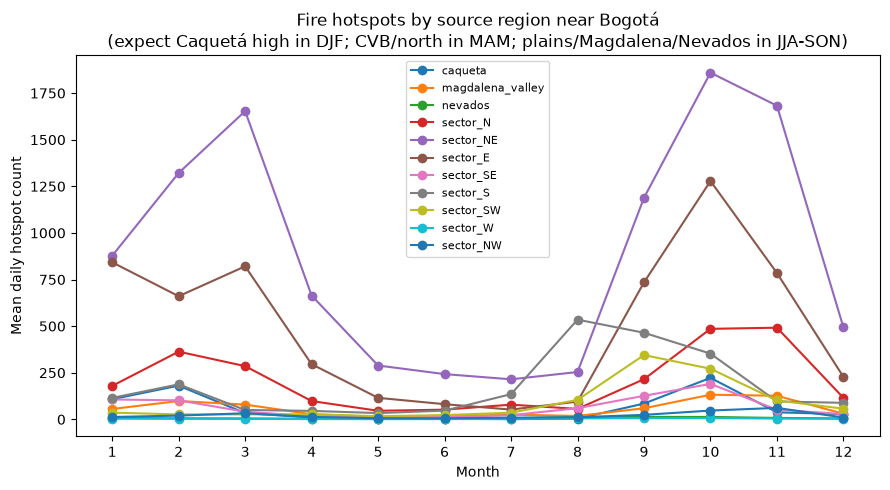

In [3]:
region_cols = [c for c in hotspots.columns if c.startswith('hotspots_')]
monthly = hotspots.set_index('date')[region_cols].groupby(
    hotspots.set_index('date').index.month
).mean()

fig, ax = plt.subplots(figsize=(9, 5))
for col in region_cols:
    ax.plot(monthly.index, monthly[col], marker='o', label=col.replace('hotspots_', ''))
ax.set_xticks(range(1, 13))
ax.set_xlabel('Month'); ax.set_ylabel('Mean daily hotspot count')
ax.set_title('Fire hotspots by source region near Bogotá\n(expect Caquetá high in DJF; CVB/north in MAM; plains/Magdalena/Nevados in JJA-SON)')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / 'hotspots_by_region_monthly.png', dpi=150)
plt.show()


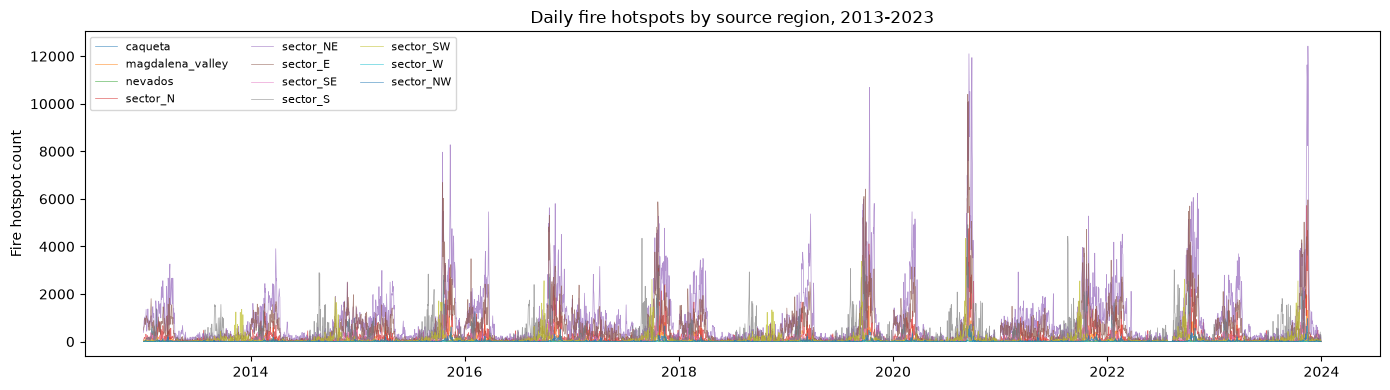

In [4]:
fig, ax = plt.subplots(figsize=(14, 4))
for col in region_cols:
    ax.plot(hotspots['date'], hotspots[col], lw=0.5, label=col.replace('hotspots_', ''), alpha=0.7)
ax.set_ylabel('Fire hotspot count')
ax.set_title('Daily fire hotspots by source region, 2013-2023')
ax.legend(fontsize=8, ncol=3)
fig.tight_layout()
fig.savefig(FIG_DIR / 'hotspots_by_region_daily_timeseries.png', dpi=150)
plt.show()


In [5]:
out_path = OUT_DIR / "bogota_hotspots_daily.parquet"
hotspots.to_parquet(out_path, index=False)
print("Saved:", out_path, hotspots.shape)


Saved: /path/to/project/Data/processed/colombia/bogota/bogota_hotspots_daily.parquet (4017, 12)
